# Previsione pre-impatto della caduta con sensore inerziale

## Obiettivo
Costruire un modello capace di riconoscere che una persona sta cadendo prima che tocchi terra,con un anticipo sufficiente ad attivare un airbag di protezione. Poichè il gonfiaggio richiede circa 200ms, la decisione deve arrivare almeno 200ms prima dell'impatto: è questo il vincolo temporale che guiderà poi tutte le scelte del modello

## Dati utilizzati
Dataset pubblico **KFall**: 32 soggetti, 2.346 cadute simulate di 15 tipi diversi e 2.729
registrazioni di attività quotidiane, acquisite a 100 Hz con un sensore inerziale indossato sulla
parte bassa della schiena. Per ogni caduta il dataset indica l'istante di inizio e l'istante di
impatto: è questa informazione che permette di misurare l'anticipo.

## Dispositivo di destinazione
Il modello dovrà essere eseguito a bordo della scheda **SensorTile.box PRO**, all'interno del
*Machine Learning Core* dell'unità inerziale LSM6DSV16X.

# CREAZIONE MODELLO

Importazione librerie e controllo esistenza dati

In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Dati = Path(r"C:\Users\feder\Desktop\tesi\Kfall")

Sensori = Dati/"sensors"
Etichette = Dati/"labels"
Figure = Dati.parent/"figure"
Figure.mkdir(exist_ok=True)

FS = 100.0 #frequenza di campionamento del dataset

print("cartella registrazioni:", Sensori.exists())
print("cartella etichette:    ", Etichette.exists())
print("soggetti trovati:      ", len([p for p in Sensori.iterdir() if p.is_dir()]))



cartella registrazioni: True
cartella etichette:     True
soggetti trovati:       32


# Verifica del dataset

Prima di costruire qualsiasi cosa bisogna verificare che i file si leggano, che le etichette si colleghino alle registrazioni giuste, e che le grandezze abbiano i valori attesi.

Come è organizzato KFall?
- una cartella per soggetto: `SA06`, `SA07`, … , `SA38`
- un file per registrazione: `S06T20R01.csv` significa soggetto **06**, task **20**, prova **01**
- i task da **20 a 34** sono le 15 cadute; tutti gli altri sono attività quotidiane
- un file Excel per soggetto con, per ogni caduta, il **frame di inizio** e il **frame di impatto**
  (il frame è il numero del campione: a 100 Hz il frame 130 corrisponde a 1,30 s)

Perchè useremo i moduli e non i singoli assi?

Il modulo di un vettore a tre componenti è la
radice quadrata della somma dei quadrati. A differenza dei singoli assi, non dipende da come è
orientato il sensore addosso alla persona: se il dispositivo ruota, i tre assi cambiano ma il
modulo resta lo stesso.


In [3]:
percorso = Sensori/"SA06"/"S06T20R01.csv"
df = pd.read_csv(percorso)

t = df["TimeStamp(s)"].values #trasforma da colonna pandas a vettore numpy

acc = np.sqrt(df.AccX**2 + df.AccY**2 + df.AccZ**2).values   # modulo accelerazione [g]
gyr = np.sqrt(df.GyrX**2 + df.GyrY**2 + df.GyrZ**2).values   # modulo velocita angolare [deg/s]

print("campioni:", len(acc), " durata:", round(t[-1], 2), "s")   # t[-1] = ultimo elemento

print("accelerazione a riposo (primo secondo):", round(acc[:100].mean(), 3), "g")
print("picco di accelerazione:", round(acc.max(), 2), "g")

campioni: 536  durata: 5.36 s
accelerazione a riposo (primo secondo): 1.003 g
picco di accelerazione: 4.88 g


In [4]:
etichette = pd.read_excel(Etichette / "SA06_label.xlsx")

etichette["Task Code (Task ID)"] = etichette["Task Code (Task ID)"].ffill()

#seleziono la riga che mi serve
riga = etichette[
    etichette["Task Code (Task ID)"].str.contains("(20)", regex=False)
    & (etichette["Trial ID"] == 1)
].iloc[0]

inizio  = int(riga["Fall_onset_frame"])
impatto = int(riga["Fall_impact_frame"])

print("tipo di caduta:", riga["Description"])
print("frame di inizio:", inizio, "->", inizio / FS, "s")      # divido per 100 per avere i secondi
print("frame di impatto:", impatto, "->", impatto / FS, "s")
print("tempo disponibile:", (impatto - inizio) / FS * 1000, "ms")   # *1000: da secondi a millisecondi


tipo di caduta: Forward fall when trying to sit down
frame di inizio: 130 -> 1.3 s
frame di impatto: 208 -> 2.08 s
tempo disponibile: 780.0 ms


Disegno della caduta

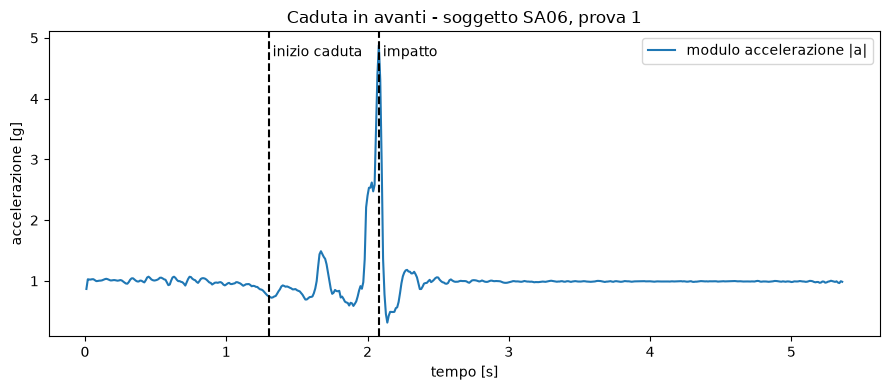

In [5]:
plt.figure(figsize=(9, 4))
plt.plot(t, acc, label="modulo accelerazione |a|")
plt.axvline(t[inizio - 1],  linestyle="--", color="black")
plt.axvline(t[impatto - 1], linestyle="--", color="black")
plt.text(t[inizio - 1],  acc.max(), " inizio caduta", va="top")
plt.text(t[impatto - 1], acc.max(), " impatto",       va="top")
plt.xlabel("tempo [s]")
plt.ylabel("accelerazione [g]")
plt.title("Caduta in avanti - soggetto SA06, prova 1")
plt.legend()
plt.tight_layout()
plt.savefig(Figure / "caduta_esempio.png", dpi=200)
plt.show()

Le registrazioni si leggono correttamente e si collegano alle
etichette; le grandezze hanno i valori attesi (circa 1 g a riposo, picco di 4,88 g all'impatto);
la fase tra l'inizio della caduta e l'impatto dura 780 ms in questo esempio. Il dataset è quindi
utilizzabile per addestrare e valutare il modello.

# LA BASELINE A SOGLIE

Prima di costruire un modello occorre sapere quanto si ottiene senza: senza un termine di paragone, i risultati del modello non sarebbero interpretabili.

L'algoritmo di riferimento è quello proposto da Jung et al. [18] nella sua forma essenziale. Durante una caduta il corpo si trova in parziale caduta libera, quindi il modulo dell'accelerazione scende sotto 1 g; contemporaneamente il tronco ruota, quindi il modulo della velocità angolare sale. La regola è:

- scatta quando '|a| < soglia_acc' **e** '|w| > soglia_gyr'

Come si misura se funziona:
- cadute riconosciute: in quante cadute la regola scatta prima dell'impatto
- anticipo: quanti millisecondi prima dell'impatto scatta — è la metrica principale
- cadute utili: quelle con anticipo di almeno 200 ms, in cui si fa in tempo a gonfiare
- falsi allarmi: in quante registrazioni di attività quotidiana la regola scatta per errore

In [6]:
def primo_scatto(a, w, soglia_acc, soglia_gyr):
    """Indice del primo campione in cui |a| < soglia_acc e |w| > soglia_gyr.
    Restituisce None se la condizione non si verifica mai."""

    condizione = (a < soglia_acc) & (w > soglia_gyr) #produce un vettore di veri/falsi, uno per campione.

    indici = np.where(condizione)[0] #restituisce gli indici dove la condizione è vera

    return int(indici[0]) if len(indici) > 0 else None

prova_a = np.array([1.0, 0.9, 0.5, 0.4])
prova_b = np.array([ 10,  20, 100, 200])
print(primo_scatto(prova_a, prova_b, 0.6, 50)) 
print(primo_scatto(prova_a, prova_b, 0.1, 50))


2
None


In [7]:
#Etichette tutte in un dizionario
etichette_tutte = {}

for file_excel in sorted(Etichette.glob("*.xlsx")):  # .glob("*.xlsx") = tutti i file xlsx
    soggetto = file_excel.stem.split("_")[0]         # .stem = nome senza estensione -> "SA06_label"
                                                     # .split("_")[0] prende cio' che sta prima di "_"
                                                     
    d = pd.read_excel(file_excel)
    d["Task Code (Task ID)"] = d["Task Code (Task ID)"].ffill()

    for _, r in d.iterrows(): #scorre tra le righe
        #cerco il numero tra le parentesi
        m = re.search(r"\((\d+)\)", str(r["Task Code (Task ID)"]))

        if m and not pd.isna(r["Fall_impact_frame"]): #controllo la presenza di righe vuote
            chiave = (soggetto, int(m.group(1)), int(r["Trial ID"]))
            etichette_tutte[chiave] = (int(r["Fall_onset_frame"]), int(r["Fall_impact_frame"]))

print("etichette caricate:", len(etichette_tutte))

#Tutte le registrazioni
cadute = []        #inserisco(accelerazione, velocità angolare, frame di impatto)
quotidiane = []    #inserisco(accelerazione, velocità angolare)

for cartella in sorted(p for p in Sensori.iterdir() if p.is_dir()):
    for file_csv in sorted(cartella.glob("*.csv")):
        # dal nome "S06T20R01" estraggo i tre numeri: soggetto, task, prova
        m = re.match(r"S(\d+)T(\d+)R(\d+)", file_csv.stem)
        if not m:
            continue
        task = int(m.group(2))
        prova = int(m.group(3))

        #usecols carica solo le sei colonne che servono
        d = pd.read_csv(file_csv, usecols=["AccX","AccY","AccZ","GyrX","GyrY","GyrZ"])
        a = np.sqrt(d.AccX**2 + d.AccY**2 + d.AccZ**2).values
        w = np.sqrt(d.GyrX**2 + d.GyrY**2 + d.GyrZ**2).values

        if 20 <= task <=34:                           #i task da 20 a 34 sono le cadute
            chiave = (cartella.name, task, prova)
            if chiave in etichette_tutte: 
                impatto_frame = etichette_tutte[chiave][1] #il secondo valore della coppia
                cadute.append((a, w, impatto_frame))

        else:
            quotidiane.append((a, w))

print("cadute:", len(cadute), " attività quotidiane:", len(quotidiane))


etichette caricate: 2346
cadute: 2346  attività quotidiane: 2729


Applico la regola a tutto il dataset e calcolo le metriche

In [8]:
def valuta(soglia_acc, soglia_gyr, anticipo_utile=200):
    """Applica la regola a tutte le cadute e a tutte le attività quotidiane."""

    anticipi = []
    riconosciute = 0
    utili = 0

    for a, w, impatto in cadute:
        #guardo solo fino al frame di impatto perchè dopo la persona è già a terra
        i = primo_scatto(a[:impatto], w[:impatto], soglia_acc, soglia_gyr)

        if i is not None:
            riconosciute += 1
            anticipo = (impatto - i) /FS *1000
            anticipi.append(anticipo)
            if anticipo >= anticipo_utile:
                utili += 1

    falsi = sum(1 for a, w in quotidiane
                if primo_scatto(a, w, soglia_acc, soglia_gyr) is not None)
    
    return {
        "soglia_acc": soglia_acc,
        "soglia_gyr": soglia_gyr,
        "riconosciute_%": 100 * riconosciute / len(cadute),
        "utili_%":        100 * utili / len(cadute),
        "falsi_allarmi_%":100 * falsi / len(quotidiane),
        "anticipo_mediano_ms": float(np.median(anticipi)),
        "anticipi": np.array(anticipi),
    }

r = valuta(0.5, 50)
print({k: round(v, 1) for k, v in r.items() if k != "anticipi"})



{'soglia_acc': 0.5, 'soglia_gyr': 50, 'riconosciute_%': 97.1, 'utili_%': 85.8, 'falsi_allarmi_%': 42.3, 'anticipo_mediano_ms': 330.0}


In [9]:
risultati = []

for soglia_acc in (0.5, 0.6, 0.7, 0.8):
    for soglia_gyr in (50, 100, 150, 200):
        r = valuta(soglia_acc, soglia_gyr)
        risultati.append(r)
        print(f"|a|<{soglia_acc:.1f} g  |w|>{soglia_gyr:3d} deg/s  ->  "
              f"riconosciute {r['riconosciute_%']:5.1f}%   utili {r['utili_%']:5.1f}%   "
              f"falsi allarmi {r['falsi_allarmi_%']:5.1f}%   "
              f"anticipo mediano {r['anticipo_mediano_ms']:5.0f} ms")

#costruisco una tabella con tutte le colonne tranne il vettore degli anticipi
tabella = pd.DataFrame([{k: v for k, v in r.items() if k != "anticipi"} for r in risultati])
tabella.to_csv(Dati.parent / "risultati_baseline.csv", index=False)
tabella

|a|<0.5 g  |w|> 50 deg/s  ->  riconosciute  97.1%   utili  85.8%   falsi allarmi  42.3%   anticipo mediano   330 ms
|a|<0.5 g  |w|>100 deg/s  ->  riconosciute  88.2%   utili  64.6%   falsi allarmi  25.9%   anticipo mediano   270 ms
|a|<0.5 g  |w|>150 deg/s  ->  riconosciute  67.2%   utili  35.4%   falsi allarmi  14.9%   anticipo mediano   200 ms
|a|<0.5 g  |w|>200 deg/s  ->  riconosciute  41.0%   utili  15.7%   falsi allarmi   9.7%   anticipo mediano   150 ms
|a|<0.6 g  |w|> 50 deg/s  ->  riconosciute  99.3%   utili  94.2%   falsi allarmi  54.6%   anticipo mediano   380 ms
|a|<0.6 g  |w|>100 deg/s  ->  riconosciute  93.5%   utili  73.2%   falsi allarmi  34.0%   anticipo mediano   300 ms
|a|<0.6 g  |w|>150 deg/s  ->  riconosciute  74.9%   utili  42.1%   falsi allarmi  17.8%   anticipo mediano   220 ms
|a|<0.6 g  |w|>200 deg/s  ->  riconosciute  47.3%   utili  19.0%   falsi allarmi  12.0%   anticipo mediano   160 ms
|a|<0.7 g  |w|> 50 deg/s  ->  riconosciute  99.9%   utili  97.0%   falsi

,soglia_acc,soglia_gyr,riconosciute_%,utili_%,falsi_allarmi_%,anticipo_mediano_ms
0,0.5,50,97.058824,85.805627,42.323195,330.0
1,0.5,100,88.192668,64.620631,25.906926,270.0
2,0.5,150,67.178176,35.379369,14.913888,200.0
3,0.5,200,41.005968,15.728900,9.673873,150.0
4,0.6,50,99.275362,94.160273,54.562111,380.0
5,0.6,100,93.478261,73.231032,34.005130,300.0
6,0.6,150,74.936061,42.114237,17.845365,220.0
7,0.6,200,47.271952,19.011083,12.019055,160.0
8,0.7,50,99.914749,97.016198,70.502015,450.0
9,0.7,100,95.780051,77.706735,46.207402,330.0


Istogramma degli anticipi

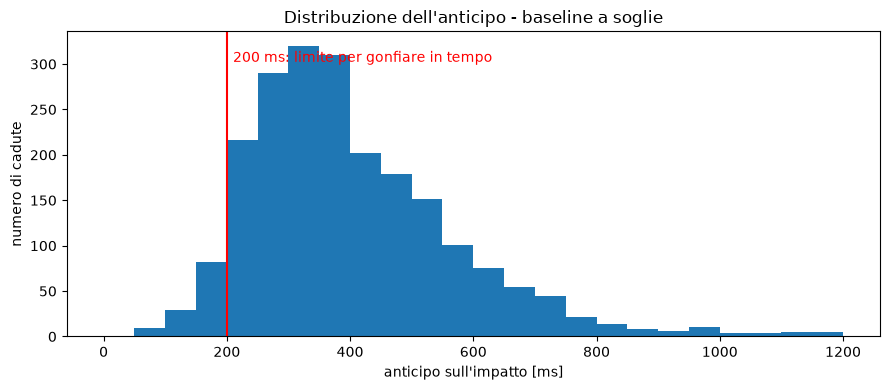

anticipo mediano: 380.0 ms
cadute sotto i 200 ms: 5.2 %


In [10]:
anticipi = valuta(0.6, 50)["anticipi"]  #scelgo una configurazione e prendo gli anticipi

plt.figure(figsize=(9, 4))
plt.hist(anticipi, bins=np.arange(0, 1250, 50)) #conta quanti valori cadono in ogni intervallo
plt.axvline(200, color="red")  #limite sotto il quale non si fa in tempo
plt.text(210, plt.ylim()[1]*0.9, "200 ms: limite per gonfiare in tempo", color="red")
plt.xlabel("anticipo sull'impatto [ms]")
plt.ylabel("numero di cadute")
plt.title("Distribuzione dell'anticipo - baseline a soglie")
plt.tight_layout()
plt.savefig(Figure / "anticipo_baseline.png", dpi=200)
plt.show()

print("anticipo mediano:", np.median(anticipi), "ms")
print("cadute sotto i 200 ms:", round(100 * (anticipi < 200).mean(), 1), "%")


Disegno ora un grafico del compromesso

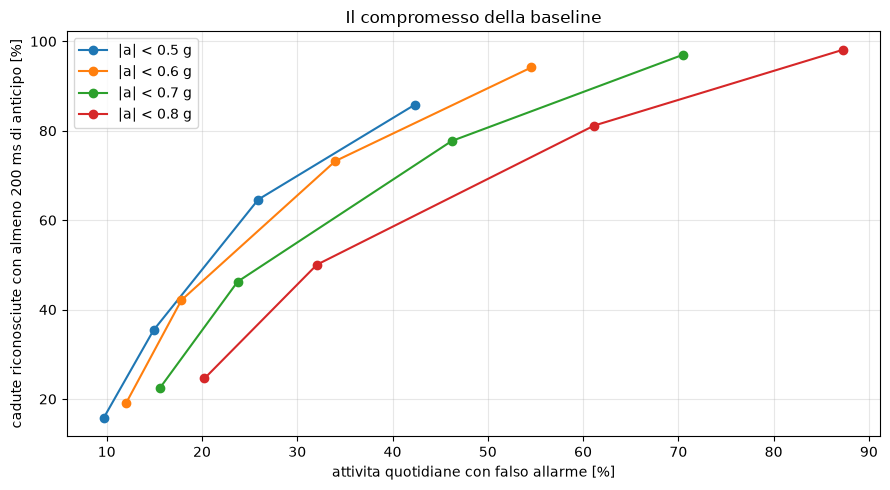

In [11]:
plt.figure(figsize=(9, 5))

#raggruppo gli stessi valori in una colonna,così ottengo un gruppo per ogni soglia di accelerazione
for soglia_acc, gruppo in tabella.groupby("soglia_acc"):
    gruppo = gruppo.sort_values("soglia_gyr")
    plt.plot(gruppo["falsi_allarmi_%"], gruppo["utili_%"],marker="o", label=f"|a| < {soglia_acc} g")

plt.xlabel("attivita quotidiane con falso allarme [%]")
plt.ylabel("cadute riconosciute con almeno 200 ms di anticipo [%]")
plt.title("Il compromesso della baseline")
plt.legend()
plt.grid(alpha=0.3)                                # griglia leggera di sfondo
plt.tight_layout()
plt.savefig(Figure / "compromesso_baseline.png", dpi=200)
plt.show()
            
            

In questa parte abbiamo visto che con soglie larghe (|a| < 0,6 g e |ω| > 50 °/s) la regola riconosce il 99,3% delle cadute e il 94,2% con anticipo sufficiente, ma genera un falso allarme nel 54,6% delle registrazioni di attività quotidiana. Stringendo le soglie i falsi allarmi calano, ma crolla il riconoscimento: con |ω| > 200 °/s si scende al 19% di cadute utili.

Il grafico del compromesso mostra che non esiste una coppia di soglie soddisfacente.

Il problema, quindi, non è riconoscere la caduta ,con soglie larghe si arriva al 99% , ma distinguerla dai movimenti bruschi della vita quotidiana.

## LE CARATTERISTICHE RICORSIVE

La baseline guardava il singolo campione: troppo poco,perchè un campione non dice se il segnale è agitato o tranquillo. Per valutare c'è bisogno di numeri che riassumano come si sta comportando il segnale: media, variabilità, escursione.

Il modo classico è la finestra: si prendono gli ultimi N campioni e si calcolano media,
varianza e picco-picco su quel blocco. Il Machine Learning Core dell'LSM6DSV16X lavora proprio
così, con finestre da 1 a 255 campioni.

Il MLC però offre anche le **caratteristiche ricorsive**. Qui non c'è nessuna
finestra: a ogni nuovo campione il valore precedente viene aggiornato con una formula, e il campione viene buttato via. Il vantaggio è decisivo per un dispositivo a batteria:

- nessun ritardo di finestra: il valore è aggiornato a ogni campione, non ogni N

Dovendo gonfiare un airbag prima dell'impatto, non possiamo permetterci di aspettare che si riempia una finestra.


Provo delle caratteristiche ricorsive che useremo su una caduta e verifico che si "accendano" prima dell'impatto.

In [12]:
#Carico una singola caduta
inizio, impatto = etichette_tutte[("SA06", 20, 1)]

d = pd.read_csv(Sensori / "SA06" / "S06T20R01.csv")

d = pd.read_csv(Sensori / "SA06" / "S06T20R01.csv")
a_es = np.sqrt(d.AccX**2 + d.AccY**2 + d.AccZ**2).values   # modulo accelerazione [g]
w_es = np.sqrt(d.GyrX**2 + d.GyrY**2 + d.GyrZ**2).values   # modulo velocita' angolare [deg/s]
t_es = np.arange(len(a_es)) / FS                           # asse dei tempi in secondi

print("campioni:", len(a_es), " inizio caduta:", inizio, " impatto:", impatto)

campioni: 536  inizio caduta: 130  impatto: 208


In [13]:
#media ricorsiva
def media_ricorsiva(x, alfa):
    #Media mobile esponenziale: y[i] = alfa*x[i] + (1-alfa)*y[i-1]."""
    #alfa e' tra 0 e 1 e decide quanto pesa il campione nuovo:
    #alfa vicino a 1  -> segue subito il segnale
    #alfa vicino a 0  -> molto liscia, ma reagisce in ritardo

    y = np.empty_like(x) #crea un vettore vuoto della stessa lunghezza e dello stesso tipo di x
    y[0] = x[0]

    for i in range(1, len(x)):
        y[i] = alfa * x[i] + (1 - alfa) * y[i-1]
    return y

Alfa = 0.10 # con 100 Hz, equivale a "ricordare" circa gli ultimi 10 campioni (0,1 s)

media = media_ricorsiva(a_es, Alfa)
print("media a riposo (primo secondo):", round(media[:100].mean(), 3), "g")

media a riposo (primo secondo): 0.994 g


In [14]:
#Varianza ricorsiva
def varianza_ricorsiva(x, alfa):
    #Varianza calcolata con due sole medie ricorsive.
    #Si usa l'identita': varianza = media(x^2) - (media di x)^2
    #Cosi' non serve conservare nessun campione passato.
    m_quadrati = media_ricorsiva(x**2, alfa)
    m_semplice = media_ricorsiva(x, alfa)

    return np.maximum(m_quadrati - m_semplice**2, 0.0) #riporta il risultato a zero per evitare valori negativi

varianza = varianza_ricorsiva(a_es, Alfa)
print("varianza a riposo:     ", round(varianza[:100].mean(), 4))
print("varianza massima prima dell'impatto:", round(varianza[:impatto].max(), 3))


varianza a riposo:      0.0018
varianza massima prima dell'impatto: 1.933


In [15]:
#minimo ricorsivo
def minimo_ricorsivo(x,c_start, ths=0.0):
    #se il segnale scende sotto il valore corrente,lo aggangia subito. Altrimenti risale pian piano verso il segnale
    y = np.empty_like(x)
    y[0] = x[0]
    c = c_start

    for i in range(1, len(x)):
        if x[i] < y[i-1] - ths:   # nuovo minimo
            y[i] = x[i]
            c = c_start           #riparte da capo con la risalita 
        else:
            y[i] = y[i-1] + (1 - c) * (x[i] - y[i - 1]) #si avvicina al segnale di una frazione
            c = c * c_start
    return y

def massimo_ricorsivo(x, c_start, ths=0.0):
   
    y = np.empty_like(x)
    y[0] = x[0]
    c = c_start
    for i in range(1, len(x)):
        if x[i] > y[i-1] + ths:
            y[i] = x[i]
            c = c_start
        else:
            y[i] = y[i-1] + (1 - c) * (x[i] - y[i-1])
            c = c * c_start
    return y


C_start = 0.98

minimo  = minimo_ricorsivo(a_es,  C_start)
massimo = massimo_ricorsivo(a_es, C_start)
picco_picco = massimo - minimo        # quarta caratteristica: l'escursione del segnale

print("picco-picco a riposo:        ", round(picco_picco[:100].mean(), 2), "g")
print("picco-picco prima dell'impatto:", round(picco_picco[:impatto].max(), 2), "g")

picco-picco a riposo:         0.06 g
picco-picco prima dell'impatto: 1.3 g


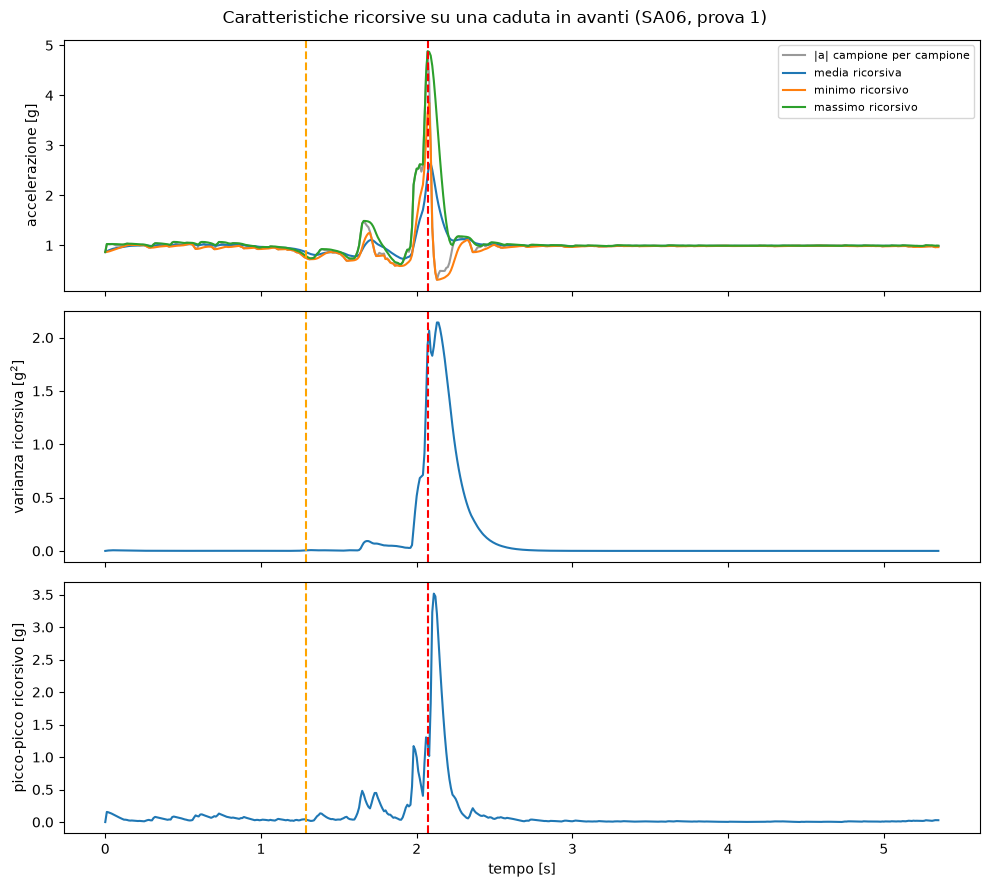

In [16]:
#lLe quattro caratteristiche su una caduta reale
fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True) #crea tre riquadri impilati; sharex=True li fa condividere l'asse del tempo

ax[0].plot(t_es, a_es,    color="0.6", label="|a| campione per campione")
ax[0].plot(t_es, media,   label="media ricorsiva")
ax[0].plot(t_es, minimo,  label="minimo ricorsivo")
ax[0].plot(t_es, massimo, label="massimo ricorsivo")
ax[0].set_ylabel("accelerazione [g]")
ax[0].legend(fontsize=8)

ax[1].plot(t_es, varianza)
ax[1].set_ylabel("varianza ricorsiva [g$^2$]")   

ax[2].plot(t_es, picco_picco)
ax[2].set_ylabel("picco-picco ricorsivo [g]")
ax[2].set_xlabel("tempo [s]")

# le due linee verticali su tutti e tre i riquadri
for riquadro in ax:                                 # ax e' un vettore di tre riquadri
    riquadro.axvline(t_es[inizio-1],  color="orange", ls="--")
    riquadro.axvline(t_es[impatto-1], color="red",    ls="--")

fig.suptitle("Caratteristiche ricorsive su una caduta in avanti (SA06, prova 1)")
plt.tight_layout()
plt.savefig(Figure / "caratteristiche_ricorsive.png", dpi=200)
plt.show()

Questa parte ci ha dimostrato che le caratteristiche ricorsive restano piatte per tutta la fase di quiete e salgono nettamente nell'intervallo tra inizio caduta e impatto.

Il salto della varianza di tre ordini di grandezza è il motivo per cui queste caratteristiche funzionano bene come ingresso di un albero decisionale: la soglia che separa i due casi è molto ampia,quindi l'albero può sceglierla senza essere fragile.



Minimo, massimo e picco-picco ricorsivi sono stati
calcolati e analizzati, ma non entrano nel modello finale. Due le ragioni:

1. **pesano poco**: nell'albero addestrato con tutte e sei le caratteristiche, le due caratteristiche di picco-picco contribuiscono insieme al 5,9% delle decisioni, contro il 48,6% della sola media dell'accelerazione. Rimuovendole le prestazioni non peggiorano, in alcuni punti migliorano;
2. **sono più difficili da riprodurre fedelmente sul sensore**: il Machine Learning Core calcola l'inviluppo con un decadimento verso un valore di riposo THS (AN5804, par. 1.3.13.2), mentre media e varianza ricorsive sono semplici filtri IIR del primo ordine, con corrispondenza diretta. Meno distanza tra il modello validato in Python e il modello eseguito dal sensore significa meno rischio di comportamenti diversi.

## TABELLE DI ADDESTRAMENTO
Il modello non guarda u segnale, ma impara da una tabella, dove ogni riga è un caso osservato, le colonne sono le caratteristiche e un' ultima colonna dice la risposta giusta.

Il modello non deve riconoscere le cadute ma deve riconoscere la finestra utile.
I campioni dopo l'impatto vengono buttati via.

A 100 Hz due campioni consecutivi sono quasi identici: non
aggiungono informazione, solo righe. Con passo 5 il modello resta a 20 righe al secondo e la tabella scende da 4 milioni di righe a circa 645.000.


In [17]:
#Raccoglie le sei caratteristiche in un'unica matrice
Nomi = ["acc_media", "acc_varianza","gyr_media", "gyr_varianza",]

def caratteristiche(a, w):
    #Calcola le quattro caratteristiche ricorsive

     return np.column_stack([
        media_ricorsiva(a, Alfa),
        varianza_ricorsiva(a, Alfa),
        media_ricorsiva(w, Alfa),
        varianza_ricorsiva(w, Alfa),
    ])

#prova su esempio
prova = caratteristiche(a_es, w_es)
print("forma della matrice:", prova.shape)

forma della matrice: (536, 4)


In [18]:
Passo = 5

#liste per accumulare i pezzi
pezzi_x, pezzi_y, pezzi_soggetto, pezzi_task = [], [], [], []
fatte = 0

for cartella in sorted(p for p in Sensori.iterdir() if p.is_dir()):
    for file_csv in sorted(cartella.glob("*.csv")):


        m = re.match(r"S(\d+)T(\d+)R(\d+)", file_csv.stem)
        if not m:
            continue
        task, prova_n = int(m.group(2)), int(m.group(3))

        d = pd.read_csv(file_csv, usecols=["AccX","AccY","AccZ","GyrX","GyrY","GyrZ"])
        a = np.sqrt(d.AccX**2 + d.AccY**2 + d.AccZ**2).values
        w = np.sqrt(d.GyrX**2 + d.GyrY**2 + d.GyrZ**2).values

        if 20 <= task <= 34:         #registrazione di caduta
            chiave = (cartella.name, task, prova_n)
            if chiave not in etichette_tutte:
                continue
            inizio_c, impatto_c = etichette_tutte[chiave]
            fine = impatto_c   #elimina tutto dopo l'impatto
            y = np.zeros(fine, dtype=np.int8)
            y[inizio_c:fine] = 1    #mette 1 solo nell'intervallo utile
        else:                       
            fine = len(a)
            y = np.zeros(fine, dtype=np.int8)

        x = caratteristiche(a, w)[:fine][::Passo]
        y = y[::Passo]

        pezzi_x.append(x.astype(np.float32))
        pezzi_y.append(y)

        pezzi_soggetto.append(np.full(len(y), cartella.name))
        pezzi_task.append(np.full(len(y), task))

        fatte += 1
        if fatte % 1000 == 0:
            print(" elaborate", fatte, "registrazioni..")

tabella = pd.DataFrame(np.vstack(pezzi_x), columns=Nomi)
tabella["etichetta"] = np.concatenate(pezzi_y)
tabella["soggetto"] = np.concatenate(pezzi_soggetto)
tabella["task"] = np.concatenate(pezzi_task)

print("registrazioni elaborate:", fatte)
print("tabella:", tabella.shape)




 elaborate 1000 registrazioni..
 elaborate 2000 registrazioni..
 elaborate 3000 registrazioni..
 elaborate 4000 registrazioni..
 elaborate 5000 registrazioni..
registrazioni elaborate: 5075
tabella: (644830, 7)


In [19]:
#Controlli
print("righe totali:", len(tabella))
print()
print("conteggio etichette:")
print(tabella["etichetta"].value_counts())        # quante righe per ciascuna classe
print()
print("percentuale di righe positive:", round(100 * tabella["etichetta"].mean(), 1), "%")
print()
print("soggetti presenti:", tabella["soggetto"].nunique())   # nunique = quanti valori diversi
print()
print("valore mediano di ogni caratteristica, per classe:")
# groupby raggruppa per etichetta, poi calcolo la mediana di ogni caratteristica in ogni gruppo
print(tabella.groupby("etichetta")[Nomi].median().round(3).to_string())


Risultati = Sensori.parent.parent / "risultati"
Risultati.mkdir(exist_ok=True)
tabella.to_csv(Risultati / "tabella_addestramento.csv", index=False)
print("\nsalvata in:", Risultati / "tabella_addestramento.csv")

righe totali: 644830

conteggio etichette:
etichetta
0    610626
1     34204
Name: count, dtype: int64

percentuale di righe positive: 5.3 %

soggetti presenti: 32

valore mediano di ogni caratteristica, per classe:
           acc_media  acc_varianza  gyr_media  gyr_varianza
etichetta                                                  
0              1.010         0.001  19.563999     39.557999
1              0.873         0.029  84.818001    461.713013

salvata in: C:\Users\feder\Desktop\tesi\risultati\tabella_addestramento.csv


Possiamo notare come la tabella delle mediane è il primo segnale he il problema è risolvibile: tutte e sei le caratteristiche si spostano nella direzione attesa, e tre di esse cambiano di oltre un ordine di grandezza tra le due classi. In particolare il giroscopio separa meglio dell'accelerometro: la varianza della velocità angolare passa da 36 a 589, mentre la media dell'accelerazione si muove solo da 1,01 a 0,87 g.

## L'ALBERO DECISIONALE
Un albero decisionale è una sequenza di domande sì/no sulle caratteristiche. Ogni nodo confronta una caratteristica con una soglia; seguendo i rami si arriva a una foglia, che contiene la risposta.

Il modello utilizza L'albero decisionale per due motivi:
- é quello che il Machine Learning Core sa eseguire. Una rete neurale non potrebbe girare dentro il sensore
- non richiede normalizzazione

**La divisione dei dati è la decisione metodologicamente più importante.**
Il modello mette da parte 8 dei 3 soggetti e li uso solo per la verifica.


In [20]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import confusion_matrix

#elenco ordinato dei 32 soggetti
soggetti = sorted(tabella["soggetto"].unique())

soggetti_verifica    = soggetti[::4]                                  # 8 soggetti tenuti da parte
soggetti_addestra    = [s for s in soggetti if s not in soggetti_verifica]   # i 24 restanti

print("soggetti di verifica:  ", soggetti_verifica)
print("soggetti addestramento:", len(soggetti_addestra))

# due maschere costruite allo stesso modo, nessuna negazione
e_addestra = tabella["soggetto"].isin(soggetti_addestra)
e_verifica = tabella["soggetto"].isin(soggetti_verifica)

x_addestra = tabella.loc[e_addestra, Nomi]
y_addestra = tabella.loc[e_addestra, "etichetta"]
x_verifica = tabella.loc[e_verifica, Nomi]
y_verifica = tabella.loc[e_verifica, "etichetta"]

print("righe di addestramento:", len(x_addestra))
print("righe di verifica:     ", len(x_verifica))


soggetti di verifica:   ['SA06', 'SA10', 'SA14', 'SA18', 'SA22', 'SA26', 'SA30', 'SA35']
soggetti addestramento: 24
righe di addestramento: 481478
righe di verifica:      163352


In [21]:
albero = DecisionTreeClassifier(
    max_depth=6,            #al massimo 6 domande in sequenza: tiene l'albero dentro i limiti del MLC
    min_samples_leaf=50,    #ogni foglia deve poggiare su almeno 50 righe: evita invenzioni su casi isolati
    random_state=0          #generatore casuale: rieseguendo ottengo lo stesso albero
)

albero.fit(x_addestra, y_addestra) #inizia l'addestramento
print("foglie dell'albero:", albero.get_n_leaves)

previsioni = albero.predict(x_verifica) #risponde su righe mai viste

#la matrice mette in riga la verità e in colonna la previsione
#ravel divide nei quattro numeri
vn, fp, fn, vp = confusion_matrix(y_verifica, previsioni).ravel()
print(f"veri negativi  {vn:7d}   falsi positivi {fp:6d}")
print(f"falsi negativi {fn:7d}   veri positivi  {vp:6d}")
print()
print("richiamo (quante righe di caduta ho preso):", round(100*vp/(vp+fn), 1), "%")
print("precisione (quante delle mie risposte 1 erano giuste):", round(100*vp/(vp+fp), 1), "%")



foglie dell'albero: <bound method BaseDecisionTree.get_n_leaves of DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=0)>
veri negativi   153596   falsi positivi    979
falsi negativi    5485   veri positivi    3292

richiamo (quante righe di caduta ho preso): 37.5 %
precisione (quante delle mie risposte 1 erano giuste): 77.1 %


Cosa ha imparato l'albero?

In [22]:
#importanza: quanto ciascuna caratteristica ha contribuito a separare le classi

importanza = pd.Series(albero.feature_importances_, index=Nomi).sort_values(ascending=False)
print("Importanza delle caratteristiche:")
print((importanza*100).round(1).to_string())
print()

#stampa le regole come testo 
print(export_text(albero, feature_names=list(Nomi), max_depth=3, decimals=3))

Importanza delle caratteristiche:
acc_media       49.6
gyr_varianza    26.0
acc_varianza    16.1
gyr_media        8.3

|--- acc_media <= 0.821
|   |--- acc_varianza <= 0.159
|   |   |--- acc_media <= 0.696
|   |   |   |--- gyr_media <= 67.940
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- gyr_media >  67.940
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- acc_media >  0.696
|   |   |   |--- gyr_media <= 93.274
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- gyr_media >  93.274
|   |   |   |   |--- truncated branch of depth 3
|   |--- acc_varianza >  0.159
|   |   |--- gyr_varianza <= 3104.237
|   |   |   |--- gyr_media <= 94.229
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- gyr_media >  94.229
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- gyr_varianza >  3104.237
|   |   |   |--- acc_varianza <= 0.261
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- acc_varianza >  0.261
|   |   |   

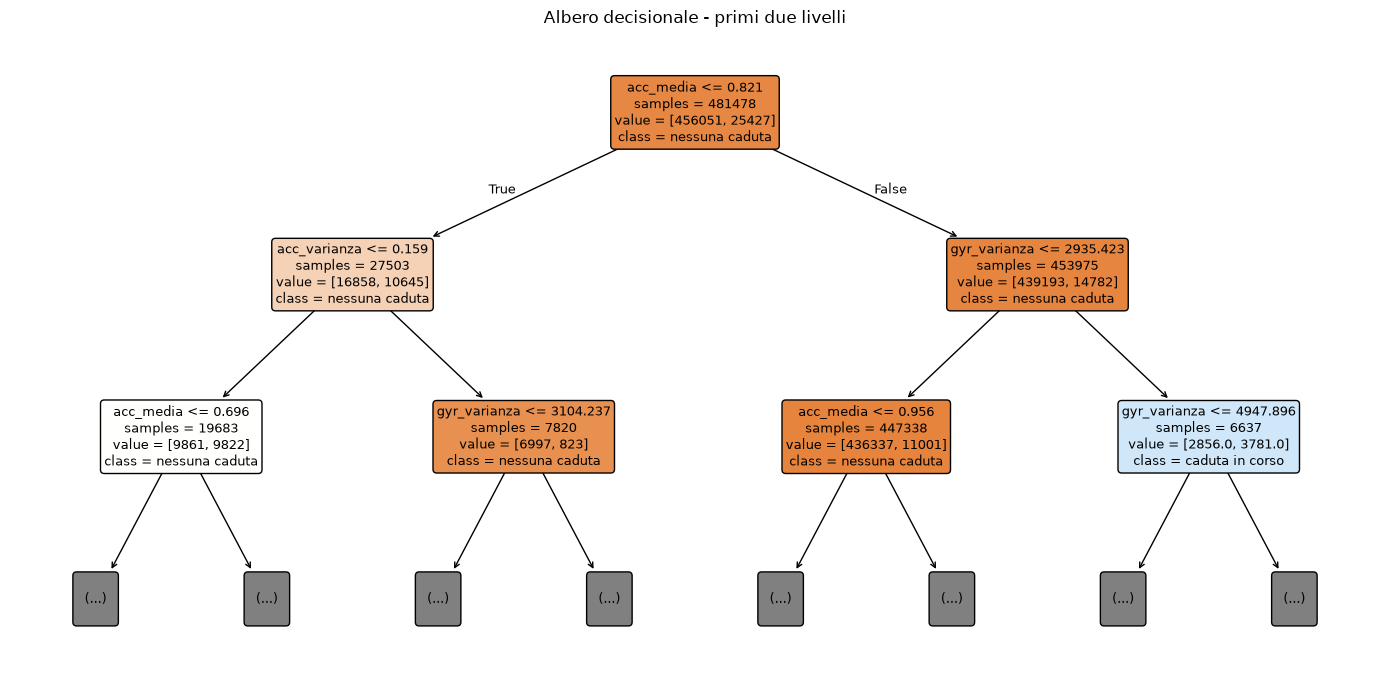

In [23]:
plt.figure(figsize=(14, 7))
plot_tree(albero,
          max_depth=2,                       # disegna solo i primi 2 livelli
          feature_names=list(Nomi),
          class_names=["nessuna caduta", "caduta in corso"],
          filled=True,                       # colora i nodi secondo la classe prevalente
          rounded=True, fontsize=9, impurity=False)
plt.title("Albero decisionale - primi due livelli")
plt.tight_layout()
plt.savefig(Figure / "albero_primi_livelli.png", dpi=200)
plt.show()

L'albero impara regole leggibili, resta nei limiti di complessità del MLC e raggiunge l'80% di precisione sulle righe di 8 soggetti mai visti in addestramento.

Il risultato però non è ancora interpretabile come prestazione del sistema, perchè è misurato sulle righe. Il dispositivo reale non classifica righe: osserva una registrazione e decide, una volta sola, se e quando gonfiare.

## VALIDAZIONE INCROCIATA E CONFRONTO CON LA BASELINE
Finora il modello ha addestrato su 24 soggetti e verificato su 8. Il risultato dipende da "quali 8": con una scelta fortunata sembrerebbe migliore di quello che è. L atecnica standard per togliere di mezzo questa fortuna è la **validazione incrociata lasciando fuori un soggetto**: addestra 32 modelli diversi, ognuno su 31 persone, e ogni persona viene valutata dal modello che non l'ha mai vista. Alla fine ogni registrazione è stata giudicata esattamente una volta, da un modello per cui era davvero nuova.

Rispetto alla parte analizzata all'inizio, il modello contava riuscita qualunque attivazione prima dell'impatto. In quel caso non era una previsione ma solo un falso allarme che per fortuna è stato seguito da una caduta. Ora invece il modello distinguerà 3 casi diversi:
- riconosciuta: la prima attivazione cade tra "Fall_onset_frame" e "Fall_impact_frame"
- troppo presto
- utile: riconosciuta e con almeno 200ms di anticpo sull'impatto

Viene applicato lo stesso criterio anche sulla prima baselone per avere un confronto onesto.



In [24]:
import pickle  #salva oggetti Python su disco

Combinazioni = [(ta, tw) for ta in (0.5, 0.6, 0.7, 0.8) for tw in (50, 100, 150, 200)]

def primo_vero(condizione, persistenza=1):
    #Primo indice in cui la condizione è vera per 'persistenza campioni consecutivi'
    #condizione è un vettore vero/falso
    b = condizione.astype(np.int8) #trasforma vero/falso in 1/0

    if persistenza > 1:
        somma = np.convolve(b, np.ones(persistenza, dtype=np.int8), mode="valid")  #calcola somma mobile e mi dice quanti 1 ci sono nei 'persistenza' campioni. valid tiene solo le posizioni in cui la finestra entra tutta
        indici = np.flatnonzero(somma == persistenza) + persistenza - 1
    else:
        indici = np.flatnonzero(b)
    return int(indici[0]) if len(indici) else None

prova_c = np.array([1,1,0,1,1,1,0], dtype=bool)
print(primo_vero(prova_c, 1)) #atteso 0
print(primo_vero(prova_c, 3)) #atteso 5

0
5


Validazione incrociata

In [25]:
risultati_v = []
for numero, sog in enumerate(soggetti, start=1):

    #addestra su tutti gli altri soggetti
    altri = tabella["soggetto"] != sog
    albero_v = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=0)
    albero_v.fit(tabella.loc[altri,Nomi], tabella.loc[altri, "etichetta"])

    #verifica su tutte le registrazioni di questo soggetto,che il modello non ha mai visto
    for file_csv in sorted((Sensori / sog).glob("*.csv")):
        m = re.match(r"S(\d+)T(\d+)R(\d+)", file_csv.stem)
        if not m:
            continue
        task, prova_n = int(m.group(2)), int(m.group(3))

        d = pd.read_csv(file_csv, usecols=["AccX","AccY","AccZ","GyrX","GyrY","GyrZ"])
        a = np.sqrt(d.AccX**2 + d.AccY**2 + d.AccZ**2).values
        w = np.sqrt(d.GyrX**2 + d.GyrY**2 + d.GyrZ**2).values


        p = albero_v.predict_proba(caratteristiche(a, w))[:,1].astype(np.float32)

        e_caduta = 20 <= task <= 34
        if e_caduta:
            chiave = (sog, task, prova_n)
            if chiave not in etichette_tutte:
                continue
            inizio_c, impatto_c = etichette_tutte[chiave]
            p, a_t, w_t = p[:impatto_c], a[:impatto_c], w[:impatto_c] #elimino tutto quello che viene dopo l'impatto
        else:
            inizio_c = impatto_c = 1
            a_t, w_t = a, w

        #per ogni combinazione calcola quando scatterenne la baseline:
        scatti_baseline = []
        for ta, tw in Combinazioni:
            i = primo_vero((a_t < ta) & (w_t > tw))
            scatti_baseline.append(i if i is not None else -1)   # -1 = non scatta mai
        
        risultati_v.append({
            "soggetto": sog, "task": task, "caduta": e_caduta,
            "inizio": inizio_c, "impatto": impatto_c,
            "p": p, "baseline": np.array(scatti_baseline, dtype=np.int32),
            
        })

print(f"  {numero}/32  {sog}  ({len(risultati_v)} registrazioni finora)")

# salva tutto, cosi' le celle seguenti ripartono da qui senza rifare il calcolo
with open(Risultati / "risultati_v.pkl", "wb") as f:   # "wb" = scrive in binario
    pickle.dump(risultati_v, f) #salva su disco

cadute_v     = [r for r in risultati_v if r["caduta"]]
quotidiane_v = [r for r in risultati_v if not r["caduta"]]
print("\nregistrazioni:", len(risultati_v), " cadute:", len(cadute_v), " quotidiane:", len(quotidiane_v))





c:\Users\feder\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\feder\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\feder\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\feder\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\feder\AppData\Local\Programs\Python\Python312\Lib\site-packages\skl

  32/32  SA38  (5075 registrazioni finora)

registrazioni: 5075  cadute: 2346  quotidiane: 2729


In [26]:
with open(Risultati / "risultati_v.pkl", "rb") as f:
    risultati_v = pickle.load(f)

In [27]:
#Valutazione dell'albero
def valuta_albero(soglia, persistenza):
    anticipi = []
    riconosciute = 0
    utili = 0
    troppo_presto = 0

    for r in cadute_v:
        i = primo_vero(r["p"] >= soglia, persistenza)
        if i is None:
            continue                      #non è mai scattato
        if i < r["inizio"]:
            troppo_presto += 1            #scatta prima che inizi la caduta
            continue
        riconosciute += 1
        anticipo = (r["impatto"] - i) / FS * 1000
        anticipi.append(anticipo)
        if anticipo >=200:
            utili += 1

    falsi = sum(1 for r in quotidiane_v if primo_vero(r["p"] >= soglia, persistenza) is not None)
    n = len(cadute_v)

    return {"soglia": soglia, "persistenza": persistenza,
            "riconosciute_%": 100*riconosciute/n, "utili_%": 100*utili/n,
            "troppo_presto_%": 100*troppo_presto/n,
            "falsi_allarmi_%": 100*falsi/len(quotidiane_v),
            "anticipo_mediano_ms": float(np.median(anticipi))}

risultati_albero = [valuta_albero(th ,pers )
                    for th in (0.3, 0.5, 0.7, 0.9)
                    for pers in (1, 3, 5)]

tab_albero = pd.DataFrame(risultati_albero)
print(tab_albero.round(1).to_string(index=False))
                    


 soglia  persistenza  riconosciute_%  utili_%  troppo_presto_%  falsi_allarmi_%  anticipo_mediano_ms
    0.3            1            76.4     75.6             23.5             75.8                470.0
    0.3            3            82.4     80.3             17.5             71.2                440.0
    0.3            5            86.9     82.9             12.7             63.5                410.0
    0.5            1            96.4     90.3              2.6             46.1                360.0
    0.5            3            96.5     86.7              1.5             40.7                340.0
    0.5            5            95.3     81.4              0.7             33.7                310.0
    0.7            1            95.3     82.2              0.9             27.4                320.0
    0.7            3            92.8     75.4              0.4             22.4                290.0
    0.7            5            89.4     67.4              0.2             17.8            

In [28]:
#Baseline con lo stesso criterio
def valuta_baseline(j):      #j è l'indice della combinazione di soglie dentro Combinazioni
    anticipi = []
    riconosciute = 0
    utili = 0
    troppo_presto = 0

    for r in cadute_v:
        i = r["baseline"][j]
        if i < 0:
            continue
        if i < r["inizio"]:
            troppo_presto += 1
            continue
        riconosciute += 1
        anticipo = (r["impatto"] - i) / FS * 1000
        anticipi.append(anticipo)
        if anticipo >= 200:
            utili += 1

    falsi = sum(1 for r in quotidiane_v if r["baseline"][j] >= 0)
    n = len(cadute_v)
    ta, tw = Combinazioni[j]

    return {"soglia_acc": ta, "soglia_gyr": tw,
            "riconosciute_%": 100*riconosciute/n, "utili_%": 100*utili/n,
            "troppo_presto_%": 100*troppo_presto/n,
            "falsi_allarmi_%": 100*falsi/len(quotidiane_v),
            "anticipo_mediano_ms": float(np.median(anticipi)) if anticipi else float("nan")}


tab_baseline = pd.DataFrame([valuta_baseline(j) for j in range(len(Combinazioni))])
print(tab_baseline.round(1).to_string(index=False))

tab_albero.to_csv(Risultati / "risultati_albero.csv", index=False)
tab_baseline.to_csv(Risultati / "risultati_baseline_loso.csv", index=False)



 soglia_acc  soglia_gyr  riconosciute_%  utili_%  troppo_presto_%  falsi_allarmi_%  anticipo_mediano_ms
        0.5          50            88.8     77.6              8.2             42.3                310.0
        0.5         100            85.5     61.9              2.7             25.9                260.0
        0.5         150            66.6     34.8              0.6             14.9                200.0
        0.5         200            41.0     15.7              0.0              9.7                150.0
        0.6          50            88.1     83.0             11.2             54.6                360.0
        0.6         100            90.1     69.8              3.4             34.0                290.0
        0.6         150            74.2     41.4              0.7             17.8                220.0
        0.6         200            47.2     19.0              0.0             12.0                160.0
        0.7          50            79.2     76.3             20.

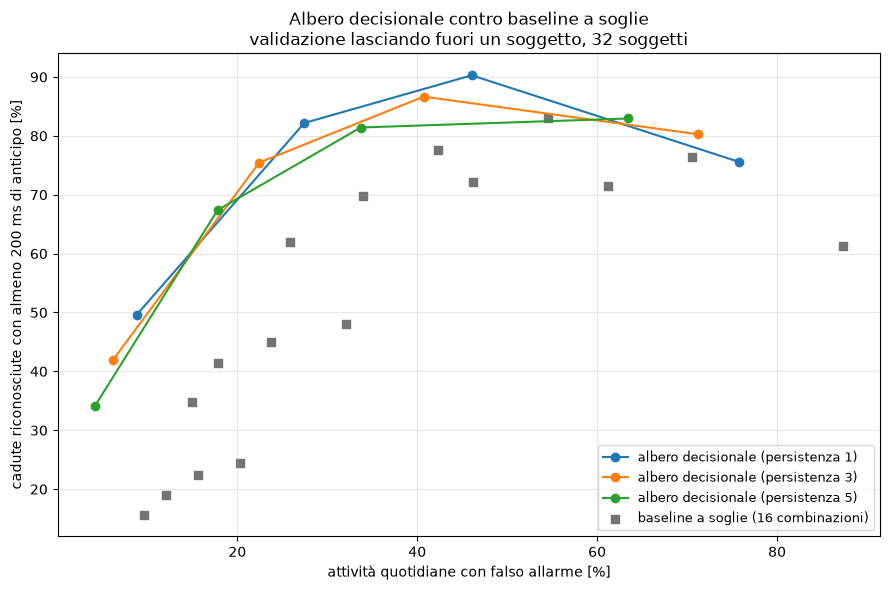

In [29]:
plt.figure(figsize=(9, 6))

# una curva per ciascun valore di persistenza, percorsa al variare della soglia
for pers in (1, 3, 5):
    punti = tab_albero[tab_albero["persistenza"] == pers].sort_values("falsi_allarmi_%")
    plt.plot(punti["falsi_allarmi_%"], punti["utili_%"],
             marker="o", label=f"albero decisionale (persistenza {pers})")

# la baseline come nuvola di punti: le 16 combinazioni di soglie
plt.scatter(tab_baseline["falsi_allarmi_%"], tab_baseline["utili_%"],
            color="0.45", marker="s", label="baseline a soglie (16 combinazioni)")

plt.xlabel("attività quotidiane con falso allarme [%]")
plt.ylabel("cadute riconosciute con almeno 200 ms di anticipo [%]")
plt.title("Albero decisionale contro baseline a soglie\nvalidazione lasciando fuori un soggetto, 32 soggetti")
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(Figure / "confronto_albero_baseline.png", dpi=200)
plt.show()

**Risultato centrale del modello**. A parità di falsi allarmi tollerati, l'albero decisionale riconosce molte più cadute in tempo utile della regola a soglie.

Il guadagno cresce man mano che si stringe sui falsi allarmi, ed è questo il punto: il problema non è riconoscere la caduta ma riconoscerla senza suonare in continuazione. E' la condizione perchè un dispositivo del genere venga davvero indossato.

**Punto di funzionamento scelto: soglia 0,7, persistenza 1.** Riconosce il 95,3% delle cadute, l'82,2% con anticipo sufficiente a gonfiare, con un anticipo mediano di 320 ms e un falso allarme nel 27,4% delle registrazioni di attività quotidiana.


Convertire l'albero nel formato richiesto da MEMS Studio

In [35]:

from pathlib import Path
import numpy as np

# Il MLC esprime la norma del giroscopio in rad/s, il modello e' addestrato in dps:
#media    dps   -> rad/s       si divide per 180/pi
#varianza dps^2 -> (rad/s)^2   si divide per (180/pi)^2
Conv = 180.0 / np.pi                     # 57,2958

Nomi_MLC = {                             # nome nel MLC, divisore per la soglia
    "acc_media":    ("F1_RECURSIVE_MEAN_ACC_V",     1.0),
    "acc_varianza": ("F1_RECURSIVE_VARIANCE_ACC_V", 1.0),
    "gyr_media":    ("F2_RECURSIVE_MEAN_GYR_V",     Conv),
    "gyr_varianza": ("F2_RECURSIVE_VARIANCE_GYR_V", Conv**2),
}
Classi = {0: "non_caduta", 1: "caduta"}

def albero_j48(modello, colonne, nomi_mlc, classi):
    t = modello.tree_
    righe = []

    def scendi(nodo, profondita):
        nome, divisore = nomi_mlc[colonne[t.feature[nodo]]]
        soglia = t.threshold[nodo] / divisore          # soglia nelle unita' del sensore
        for figlio, segno in ((t.children_left[nodo], "<="), (t.children_right[nodo], ">")):
            testa = "|   " * profondita + f"{nome} {segno} {soglia:.6f}"
            if t.children_left[figlio] == -1:
                righe.append(f"{testa}: {classi[int(t.value[figlio][0].argmax())]} "
                             f"({t.n_node_samples[figlio]}.0)")
            else:
                righe.append(testa)
                scendi(figlio, profondita + 1)

    scendi(0, 0)
    righe += ["", f"Number of Leaves  : \t{modello.get_n_leaves()}",
                  f"Size of the tree : \t{t.node_count}"]
    return "\n".join(righe)

testo = albero_j48(albero, Nomi, Nomi_MLC, Classi)
Path(r"C:\Users\feder\Desktop\tesi\sensore\albero_mlc.txt").write_text(testo, encoding="utf-8")
print(testo[:600])


F1_RECURSIVE_MEAN_ACC_V <= 0.821112
|   F1_RECURSIVE_VARIANCE_ACC_V <= 0.158676
|   |   F1_RECURSIVE_MEAN_ACC_V <= 0.696049
|   |   |   F2_RECURSIVE_MEAN_GYR_V <= 1.185776
|   |   |   |   F1_RECURSIVE_VARIANCE_ACC_V <= 0.071318
|   |   |   |   |   F1_RECURSIVE_MEAN_ACC_V <= 0.601248: caduta (1046.0)
|   |   |   |   |   F1_RECURSIVE_MEAN_ACC_V > 0.601248: caduta (1229.0)
|   |   |   |   F1_RECURSIVE_VARIANCE_ACC_V > 0.071318
|   |   |   |   |   F2_RECURSIVE_MEAN_GYR_V <= 0.690101: non_caduta (363.0)
|   |   |   |   |   F2_RECURSIVE_MEAN_GYR_V > 0.690101: non_caduta (445.0)
|   |   |   F2_RECURS
